# LFANet-NoDepthwise Ablation

In [1]:
import cv2
import os
import numpy as np
import pandas as pd
from math import exp, sqrt
import matplotlib.pyplot as plt
from sklearn import svm, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels
import matplotlib.image as mpimg
from sklearn.utils import shuffle
import keras
import tensorflow as tf

import tensorflow.keras.backend as K
from keras import Input
from keras.models import Model
from keras.layers import Dense, Dropout, Activation, Flatten
from keras.layers import BatchNormalization, Concatenate, Add, DepthwiseConv2D, GlobalAveragePooling2D, SeparableConv2D
from tensorflow.keras.optimizers import SGD,RMSprop,Adam,Adagrad
from keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Reshape, Softmax, Permute, Lambda

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vibhingupta028/liver-histopathology-fibrosis-ultrasound-images")

print("Path to dataset files:", path)

100%|██████████| 205M/205M [00:03<00:00, 58.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/vibhingupta028/liver-histopathology-fibrosis-ultrasound-images/versions/2


# **Splitting the Data into Training and Testing**

In [3]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from keras.utils import to_categorical

# Define path to the main directory
# data_path = 'rice'
# Define class names
class_names = ['F0', 'F1', 'F2', 'F3', 'F4']
class_to_label = {name: idx for idx, name in enumerate(class_names)}

img_data_list = []
labels = []

# Load images and labels
# Corrected path to account for the nested 'Dataset' directory
dataset_path = os.path.join(path, 'Dataset', 'Dataset')
for dataset in class_names:
    img_list = os.listdir(os.path.join(dataset_path, dataset))
    print(f'Loaded images from dataset-{dataset}, total: {len(img_list)}')

    for img in img_list:
        img_path = os.path.join(dataset_path, dataset, img)
        input_img = cv2.imread(img_path)
        if input_img is None:
            continue
        input_img_resize = cv2.resize(input_img, (128, 128))
        img_data_list.append(input_img_resize)
        labels.append(class_to_label[dataset])  # Use mapped label

Loaded images from dataset-F0, total: 2114
Loaded images from dataset-F1, total: 861
Loaded images from dataset-F2, total: 793
Loaded images from dataset-F3, total: 857
Loaded images from dataset-F4, total: 1698


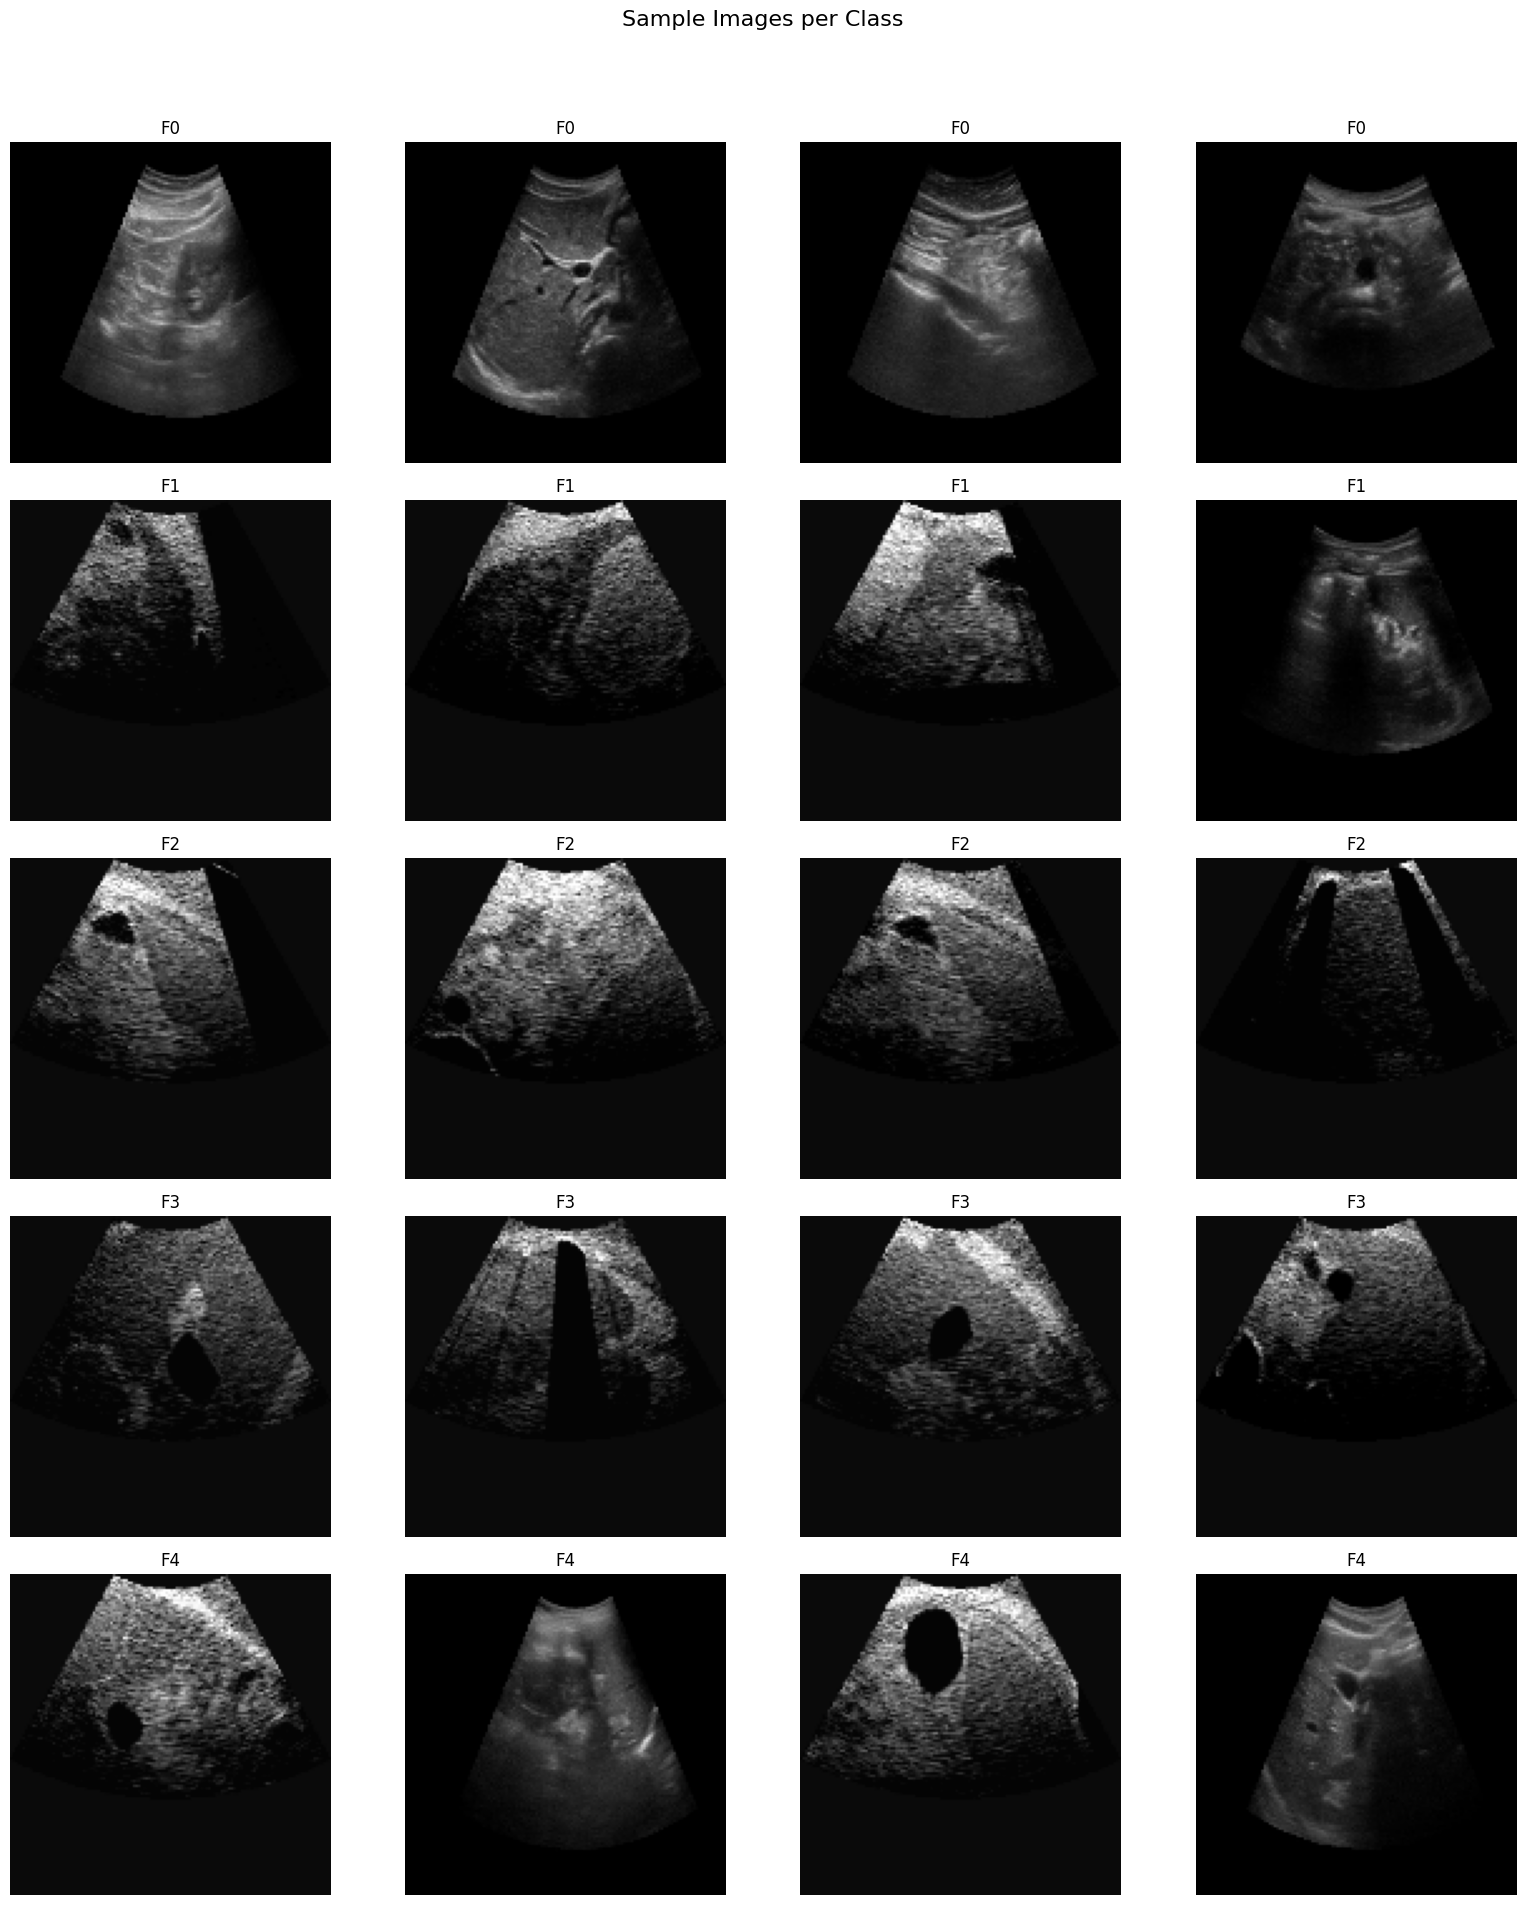

In [4]:
import matplotlib.pyplot as plt
import random

num_images_per_class = 4
plt.figure(figsize=(16, 4 * len(class_names)))

for idx, class_name in enumerate(class_names):
    class_indices = [i for i, label in enumerate(labels) if label == idx]
    sampled_indices = random.sample(class_indices, min(num_images_per_class, len(class_indices)))

    for j, rand_idx in enumerate(sampled_indices):
        plt_idx = idx * num_images_per_class + j + 1
        plt.subplot(len(class_names), num_images_per_class, plt_idx)
        plt.imshow(img_data_list[rand_idx])
        plt.title(class_name)
        plt.axis('off')

plt.suptitle("Sample Images per Class", fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


In [5]:
# Convert to NumPy arrays and normalize
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels)

# One-hot encode labels
num_classes = len(class_names)
labels_one_hot = to_categorical(labels, num_classes)

# Train / temp split (70 / 30)
x_train, x_temp, y_train, y_temp = train_test_split(
    data,
    labels_one_hot,
    test_size=0.3,
    stratify=labels,
    random_state=42
)

# Stratify validation / test split (15 / 15)
y_temp_labels = np.argmax(y_temp, axis=1)

x_val, x_test, y_val, y_test = train_test_split(
    x_temp,
    y_temp,
    test_size=0.5,
    stratify=y_temp_labels,
    random_state=42
)

# Shuffle
x_train, y_train = shuffle(x_train, y_train, random_state=42)
x_val, y_val = shuffle(x_val, y_val, random_state=42)
x_test, y_test = shuffle(x_test, y_test, random_state=42)


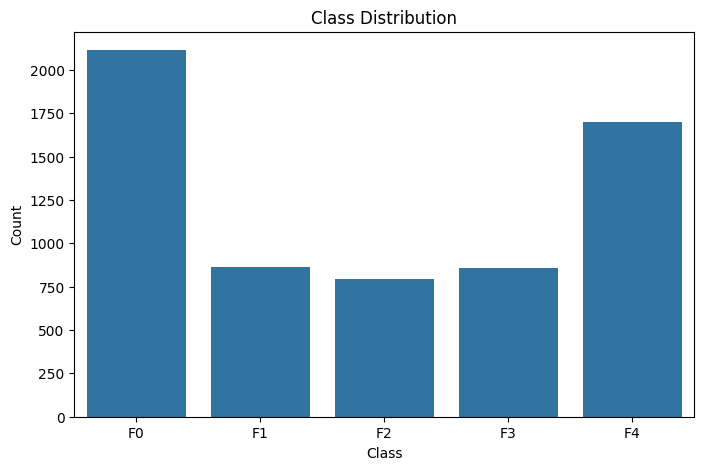

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot class distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=np.argmax(labels_one_hot, axis=1))
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=range(num_classes), labels=class_names)
plt.show()

In [7]:
# Reshape
x_train = x_train.reshape(-1, 128, 128, 3)
x_val = x_val.reshape(-1, 128, 128, 3)
x_test = x_test.reshape(-1, 128, 128, 3)

# Confirm shapes
print("Train shape:", x_train.shape)
print("Validation shape:", x_val.shape)
print("Test shape:", x_test.shape)

Train shape: (4426, 128, 128, 3)
Validation shape: (948, 128, 128, 3)
Test shape: (949, 128, 128, 3)


In [8]:
import tensorflow
METRICS = [tensorflow.keras.metrics.CategoricalAccuracy(name='accuracy'),
           tensorflow.keras.metrics.Precision(name='precision'),
           tensorflow.keras.metrics.Recall(name='recall'),
           tensorflow.keras.metrics.AUC(name='auc')]

In [9]:
from tensorflow.keras.layers import Dense, Reshape, Softmax, Permute, Add, Lambda
import tensorflow.keras.backend as K

def self_attention(input_feature_map):
    shape = K.int_shape(input_feature_map)  # (batch_size, height, width, channels)
    batch_size, height, width, channels = shape

    # Flatten the spatial dimensions (height, width) to treat them as sequence elements
    flat_feature_map = Reshape((height * width, channels))(input_feature_map)  # (batch_size, height*width, channels)

    # Compute Query, Key, and Value matrices with more complexity
    query_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 4)
    key_dense1 = Dense(channels // 4, activation='relu')(flat_feature_map)     # (batch_size, height*width, channels // 4)
    value_dense1 = Dense(channels // 2, activation='relu')(flat_feature_map)   # (batch_size, height*width, channels // 2)

    query = Dense(channels // 8)(query_dense1)  # (batch_size, height*width, channels // 8)
    key = Dense(channels // 8)(key_dense1)      # (batch_size, height*width, channels // 8)
    value = Dense(channels)(value_dense1)       # (batch_size, height*width, channels)

    # Transpose the Key for dot product
    key_transposed = Permute((2, 1))(key)  # (batch_size, channels // 8, height*width)

    # Compute attention scores (dot product between Query and transposed Key)
    attention_scores = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, height * width))([query, key_transposed])

    # Apply softmax to the attention scores
    attention_scores = Softmax()(attention_scores)  # (batch_size, height*width, height*width)

    # Apply the attention scores to the Value matrix
    attention_output = Lambda(lambda x: K.batch_dot(x[0], x[1]),
                              output_shape=(height * width, channels))([attention_scores, value])  # (batch_size, height*width, channels)

    # Reshape the attention output back to the original feature map shape
    attention_output = Reshape((height, width, channels))(attention_output)

    # Add the input to the attention output (residual connection)
    output = Add()([input_feature_map, attention_output])

    return output

### LFANet-NoDepthwise Model Definition

In [10]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Conv2D, BatchNormalization, ReLU, Multiply,
    Concatenate, GlobalAveragePooling2D, Dense, Activation, Add, Dropout
)
from tensorflow.keras.models import Model

# Input Layer
input_layer = tf.keras.Input(shape=(128, 128, 3))

# Initial Convolution Block
x = Conv2D(32, (3, 3), strides=(2, 2), padding='same', activation='relu')(input_layer)
x = BatchNormalization()(x)
x = Conv2D(64, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Replaced Depthwise Separable Convolution Block with standard Conv2D
x = Conv2D(
    filters=K.int_shape(x)[-1],
    kernel_size=(3,3),
    padding='same',
    strides=(1,1),
    activation=None
)(x)
x = BatchNormalization()(x)
x = ReLU()(x)

# Dilated Convolution Branches for Multi-scale Features
x1 = Conv2D(128, (3, 3), dilation_rate=1, padding='same', activation='relu')(x)
x1 = BatchNormalization()(x1)
x2 = Conv2D(128, (3, 3), dilation_rate=3, padding='same', activation='relu')(x)
x2 = BatchNormalization()(x2)
x3 = Conv2D(128, (3, 3), dilation_rate=5, padding='same', activation='relu')(x)
x3 = BatchNormalization()(x3)

# Adding Branch Outputs
A1 = Add()([x1, x2, x3])

# Intermediate Convolutional Block
x4 = Conv2D(128, (3, 3), padding='same', activation='relu')(A1)
x4 = BatchNormalization()(x4)

x = self_attention(x4)

# Concatenation Block
C1 = Concatenate()([x, x2, x3])
x5 = Conv2D(128, (3, 3), padding='same', activation='relu')(C1)

# Residual Connection
C2 = Concatenate()([x5, x])
x = Conv2D(256, (3, 3), padding='same', activation='relu')(C2)
x = BatchNormalization()(x)

# Replaced Expanded Depthwise Separable Convolution Block with standard Conv2D
x = Conv2D(
    filters=K.int_shape(x)[-1],
    kernel_size=(3,3),
    padding='same',
    strides=(1,1),
    activation=None
)(x)
x = BatchNormalization()(x)
x = ReLU()(x)
x = Conv2D(256, (1, 1), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Additional Residual Connection
residual = Conv2D(256, (1, 1), padding='same', activation='relu')(C2)
x = Add()([x, residual])

# Further Convolutional Layers
x = Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)
x = Conv2D(512, (3, 3), padding='same', activation='relu')(x)
x = BatchNormalization()(x)

# Global Pooling
x = GlobalAveragePooling2D()(x)

# Fully Connected Layers
x = Dense(512, activation='relu')(x)
x = Dense(256, activation='relu')(x)
output = Dense(num_classes, activation='softmax')(x)

# Model Compilation
model_no_depthwise = Model(inputs=input_layer, outputs=output)
model_no_depthwise.compile(optimizer='adam', loss='categorical_crossentropy', metrics= METRICS)
model_no_depthwise.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │     73,856 │ re_lu[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │ batch_normalizat… │
│                     │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │    147,584 │ add[0][0]         │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,379,941 (16.71 MB)

 Trainable params: 4,375,525 (16.69 MB)

 Non-trainable params: 4,416 (17.25 KB)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

In [12]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

In [13]:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_no_depthwise = ModelCheckpoint(
    filepath='model_no_depthwise-{epoch:03d}-{accuracy:.3f}-{val_accuracy:.3f}.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

In [14]:
import time
start_train = time.time()
history = model_no_depthwise.fit(x_train, y_train, batch_size = 16, epochs = 50,
                    validation_data = (x_val , y_val), callbacks=[early_stop, lr_scheduler, checkpoint_no_depthwise], verbose =1)
end_train = time.time()
training_time = end_train - start_train
print(f"\nTraining time: {training_time:.2f} seconds")

Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.4906 - auc: 0.8170 - loss: 1.1478 - precision: 0.6439 - recall: 0.3120
Epoch 1: val_accuracy improved from None to 0.12764, saving model to model_no_depthwise-001-0.537-0.128.keras

Epoch 1: finished saving model to model_no_depthwise-001-0.537-0.128.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 228s 642ms/step - accuracy: 0.5366 - auc: 0.8506 - loss: 1.0336 - precision: 0.7072 - recall: 0.3640 - val_accuracy: 0.1276 - val_auc: 0.4104 - val_loss: 5.2120 - val_precision: 0.1281 - val_recall: 0.1213 - learning_rate: 0.0010
Epoch 2/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step - accuracy: 0.6222 - auc: 0.9014 - loss: 0.8374 - precision: 0.8085 - recall: 0.4830
Epoch 2: val_accuracy improved from 0.12764 to 0.47890, saving model to model_no_depthwise-002-0.624-0.479.keras

Epoch 2: finished saving model to model_no_depthwise-002-0.624-0.479.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 128s 460ms/step - accuracy: 0.6236 - auc: 0.9024 - loss: 0.

In [15]:
# To load the best weights, you would typically load from the filepath saved by ModelCheckpoint.
# The `EarlyStopping` callback with `restore_best_weights=True` already ensures the model
# has the best weights after training. If you want to explicitly load, find the best checkpoint file.
# For example:
# best_model_path = 'path/to/your/best/model_no_depthwise-XXX.keras'
# model_no_depthwise.load_weights(best_model_path)
print("Model training complete. Best weights should be restored by EarlyStopping.")

Model training complete. Best weights should be restored by EarlyStopping.


In [16]:
loss, acc, prec, rec, auc = model_no_depthwise.evaluate(x_test, y_test, verbose=1)
print(f"\nTest Loss: {loss:.4f}")
print(f"Test Accuracy: {acc:.4f}")
print(f"Test Precision: {prec:.4f}")
print(f"Test Recall: {rec:.4f}")
print(f"Test AUC: {auc:.4f}")

30/30 ━━━━━━━━━━━━━━━━━━━━ 53s 958ms/step - accuracy: 0.9673 - auc: 0.9917 - loss: 0.1727 - precision: 0.9683 - recall: 0.9642

Test Loss: 0.1727
Test Accuracy: 0.9673
Test Precision: 0.9683
Test Recall: 0.9642
Test AUC: 0.9917


In [17]:
# -----------------------------------------------------------------
# INFERENCE TIME (measure prediction speed)
# -----------------------------------------------------------------
start_inf = time.time()
preds = model_no_depthwise.predict(x_test)
end_inf = time.time()

inference_time = end_inf - start_inf
print(f"\nInference time on test set: {inference_time:.2f} seconds")

num_images = len(x_test)
if num_images > 0:
    ms_per_image = (inference_time / num_images) * 1000
    print(f"Milliseconds per image: {ms_per_image:.2f} ms/image")
else:
    print("No images in test set for inference time calculation.")

30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 366ms/step

Inference time on test set: 12.87 seconds
Milliseconds per image: 13.56 ms/image


In [18]:
# -----------------------------------------------------------------
# SAVE MODEL AND CHECK SIZE
# -----------------------------------------------------------------
import os
import tensorflow as tf
from datetime import datetime

os.makedirs("saved_models_no_depthwise", exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Keras v3 format
keras_path = f"saved_models_no_depthwise/livermodel_no_depthwise_{timestamp}.keras"
model_no_depthwise.save(keras_path)
print(f"Saved Keras model: {keras_path}")

# Print model size
model_size_mb = os.path.getsize(keras_path) / (1024 * 1024)
print(f"Model size: {model_size_mb:.2f} MB")

# Also print model parameters
num_params = model_no_depthwise.count_params()
print(f"Total parameters: {num_params}")

trainable_params = np.sum([K.count_params(w) for w in model_no_depthwise.trainable_weights])
print(f"Trainable parameters: {trainable_params}")

non_trainable_params = np.sum([K.count_params(w) for w in model_no_depthwise.non_trainable_weights])
print(f"Non-trainable parameters: {non_trainable_params}")

Saved Keras model: saved_models_no_depthwise/livermodel_no_depthwise_20260710_132545.keras
Model size: 50.32 MB
Total parameters: 4379941
Trainable parameters: 4375525
Non-trainable parameters: 4416


In [19]:
import shutil

shutil.make_archive(
    "liver_models_bundle_no_depthwise",
    "zip",
    "saved_models_no_depthwise"
)

print("Zipped all models into liver_models_bundle_no_depthwise.zip")

Zipped all models into liver_models_bundle_no_depthwise.zip


In [20]:
from google.colab import files
files.download("liver_models_bundle_no_depthwise.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Confusion Matrix and ROC Curve for LFANet-NoDepthwise

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 319ms/step


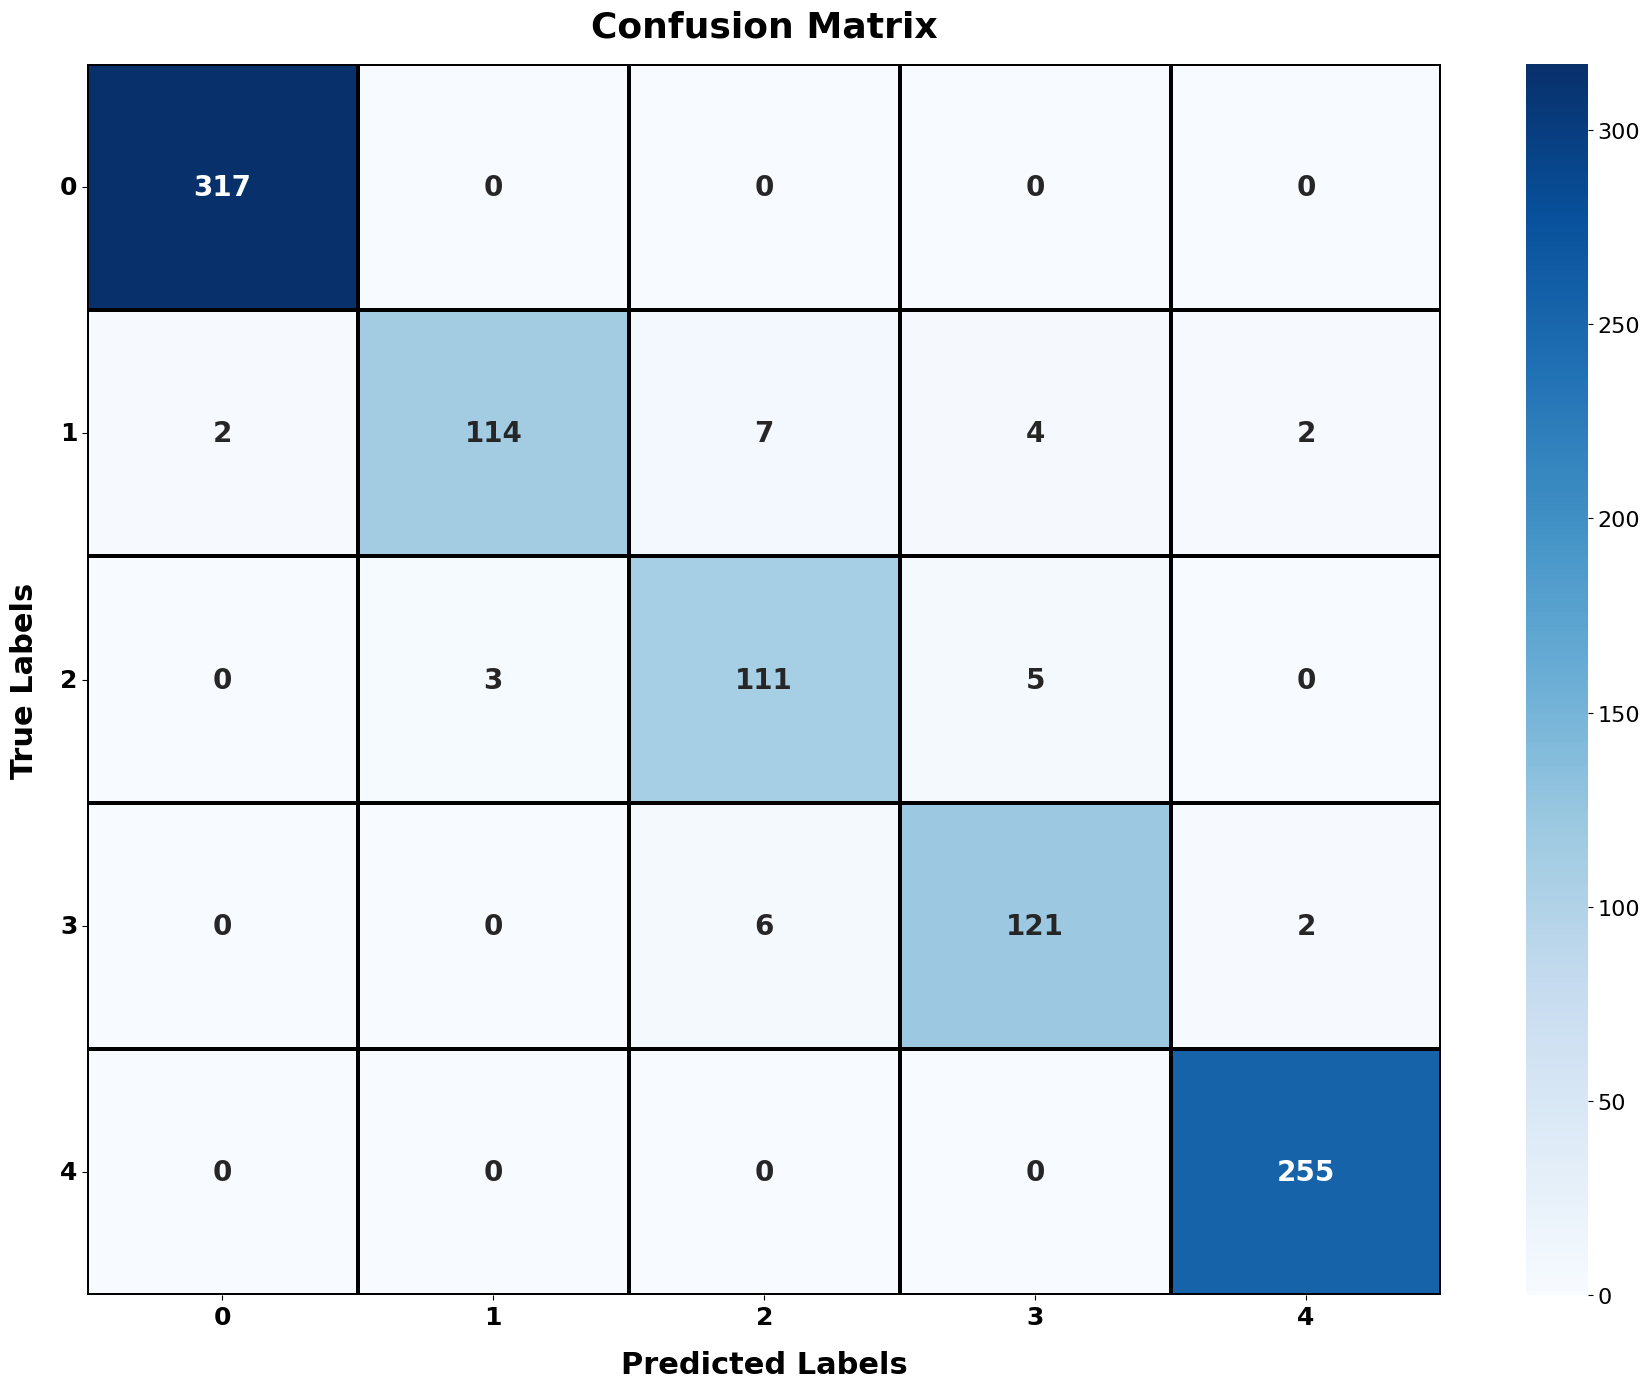

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels

# Predictions
y_pred = model_no_depthwise.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# True labels
y_true = np.argmax(y_test, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes)

# Plot
plt.figure(figsize=(18, 14))

ax = sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    annot_kws={"size": 20, "weight": "bold"},
    linewidths=1.5,
    linecolor="black"
)

# Axis labels and title
ax.set_title("Confusion Matrix", fontsize=26, fontweight="bold", pad=20)
ax.set_xlabel("Predicted Labels", fontsize=22, fontweight="bold", labelpad=15)
ax.set_ylabel("True Labels", fontsize=22, fontweight="bold", labelpad=15)

# Tick labels
labels = unique_labels(y_true)
ax.set_xticklabels(labels, fontsize=18, fontweight="bold")
ax.set_yticklabels(labels, fontsize=18, fontweight="bold", rotation=0)

# Color bar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=16)

plt.tight_layout()
plt.show()

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 321ms/step


/tmp/ipykernel_1142/739700234.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap("tab10", num_classes)


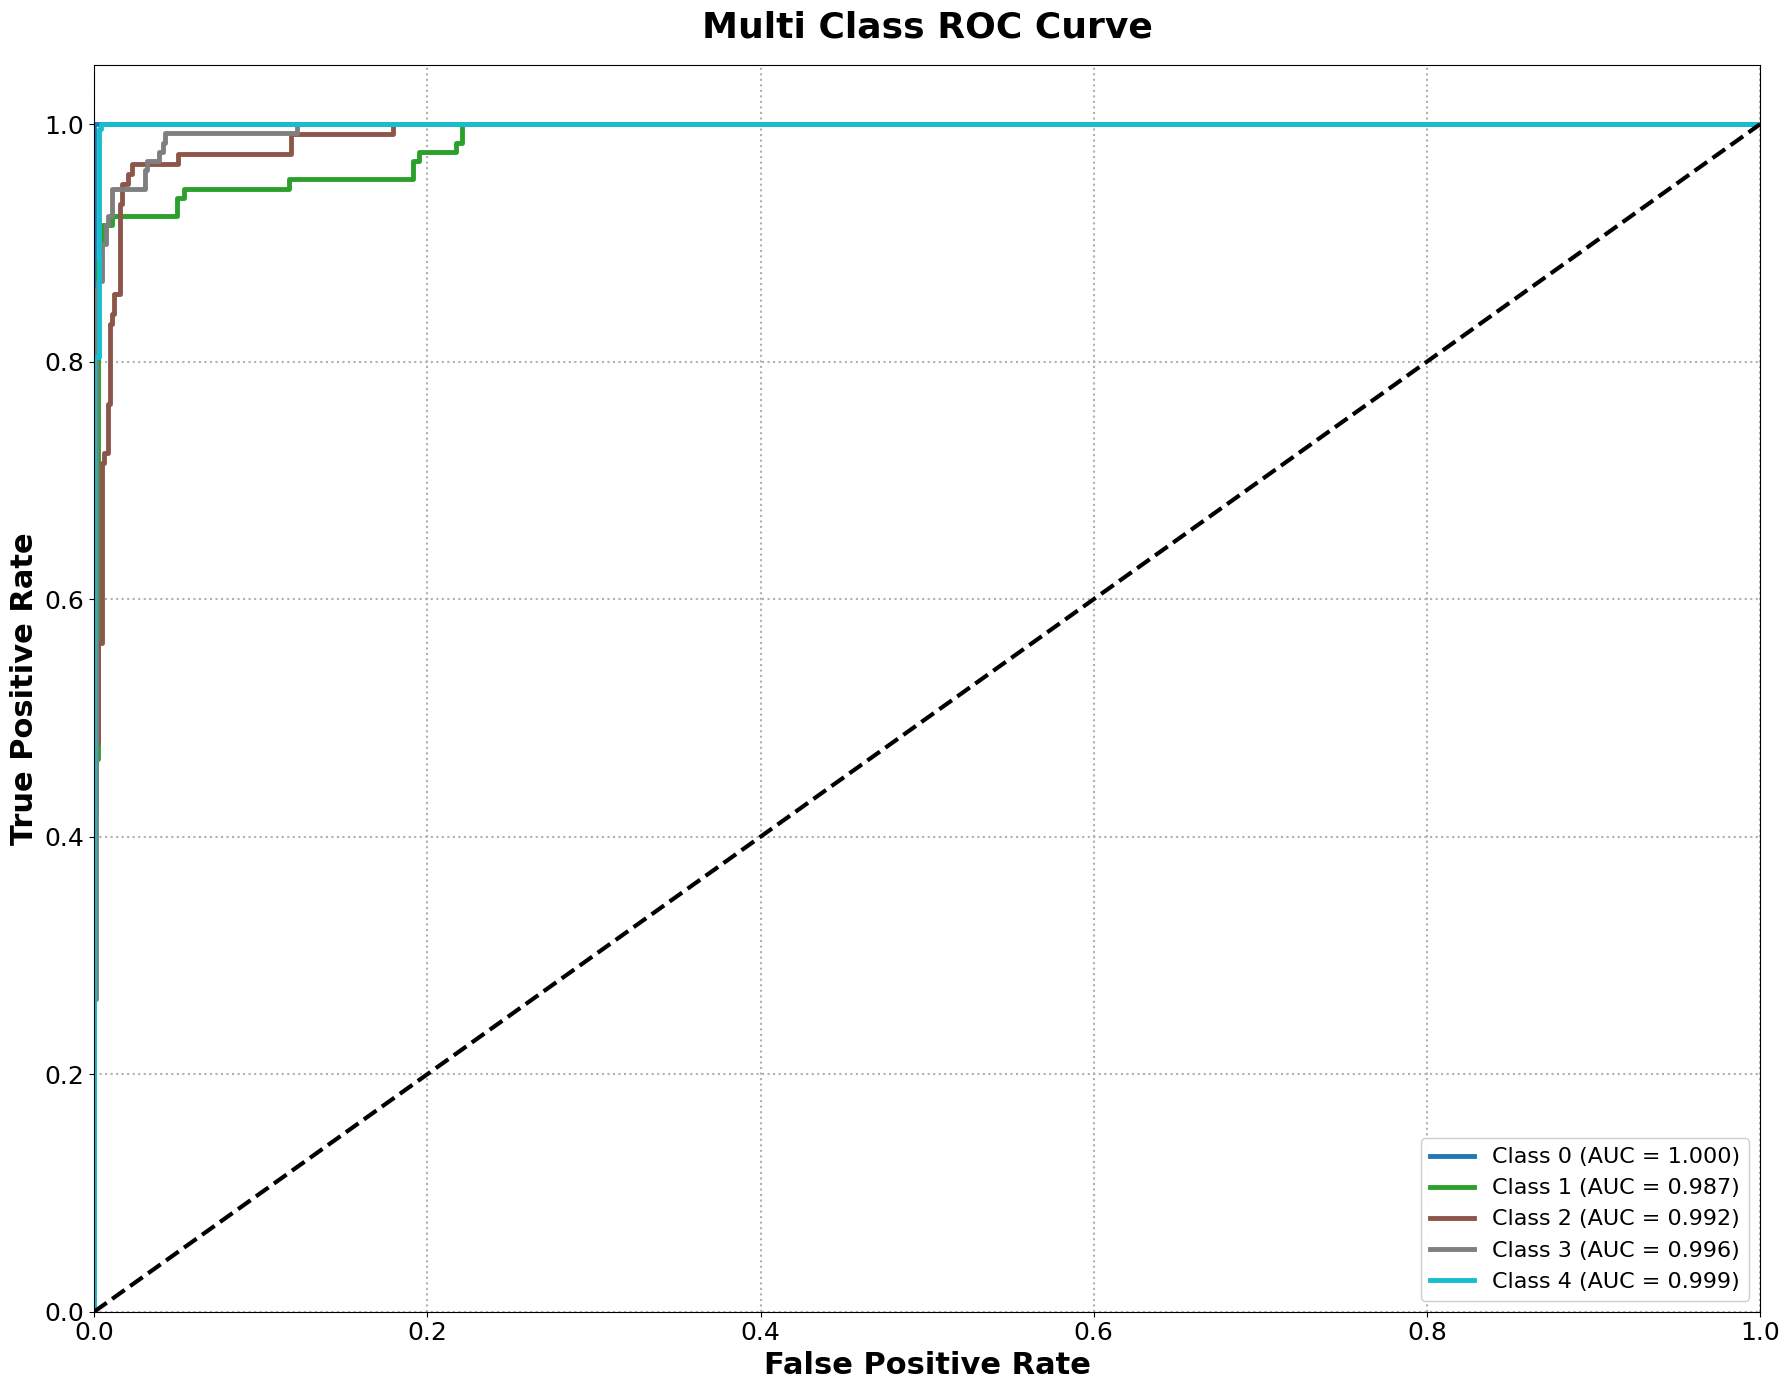

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# num_classes is already defined

# Evaluate the model (already done, but re-running for completeness for ROC)
# loss, acc, prec, rec, auc_score = model_no_depthwise.evaluate(x_test, y_test, verbose=0)

# Predictions
y_pred = model_no_depthwise.predict(x_test)

# Binarize labels
y_true_bin = label_binarize(y_test, classes=np.arange(num_classes))

# ROC computation
fpr, tpr, roc_auc = {}, {}, {}
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(18, 14))

colors = plt.cm.get_cmap("tab10", num_classes)

for i in range(num_classes):
    plt.plot(
        fpr[i],
        tpr[i],
        linewidth=3.5,
        color=colors(i),
        label=f"Class {i} (AUC = {roc_auc[i]:.3f})"
    )

# Reference line
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=3, color="black")

# Axis limits
plt.xlim(0, 1)
plt.ylim(0, 1.05)

# Labels and title (large and clear)
plt.xlabel("False Positive Rate", fontsize=22, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=22, fontweight="bold")
plt.title("Multi Class ROC Curve", fontsize=26, fontweight="bold", pad=20)

# Ticks
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# Legend
plt.legend(
    loc="lower right",
    fontsize=16,
    frameon=True,
    framealpha=0.95
)

# Grid for readability
plt.grid(True, linestyle=":", linewidth=1.5)

plt.tight_layout()
plt.show()

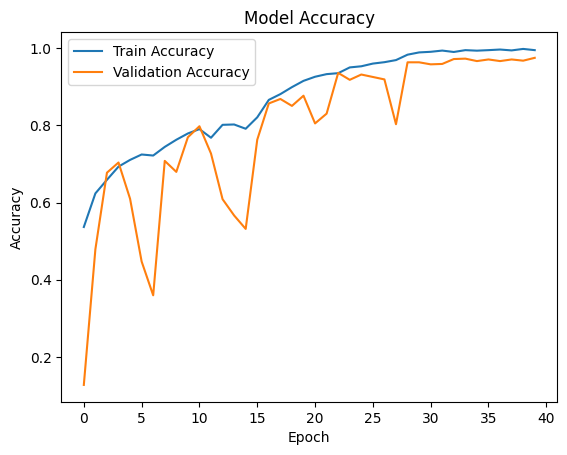

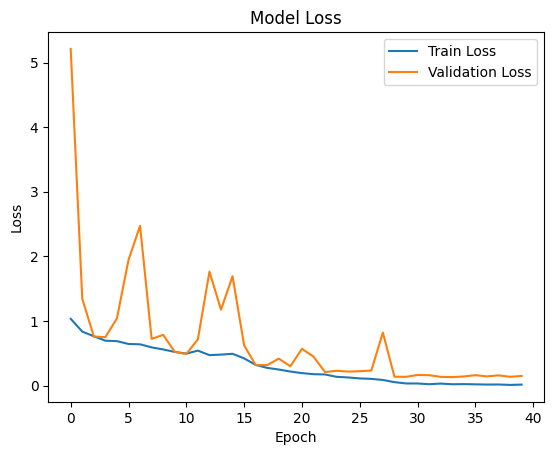

In [23]:
import matplotlib.pyplot as plt

def plot_accuracy(history):
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

def plot_loss(history):
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_accuracy(history)
plot_loss(history)

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 321ms/step
Class-wise metrics:
Class 0:
  Precision   : 0.9937
  Recall      : 1.0000
  Specificity : 0.9968
  PLR         : 316.0000
  NLR         : 0.0000
  F1-Score    : 0.9969

Class 1:
  Precision   : 0.9744
  Recall      : 0.8837
  Specificity : 0.9963
  PLR         : 241.5504
  NLR         : 0.1167
  F1-Score    : 0.9268

Class 2:
  Precision   : 0.8952
  Recall      : 0.9328
  Specificity : 0.9843
  PLR         : 59.5540
  NLR         : 0.0683
  F1-Score    : 0.9136

Class 3:
  Precision   : 0.9308
  Recall      : 0.9380
  Specificity : 0.9890
  PLR         : 85.4608
  NLR         : 0.0627
  F1-Score    : 0.9344

Class 4:
  Precision   : 0.9846
  Recall      : 1.0000
  Specificity : 0.9942
  PLR         : 173.5000
  NLR         : 0.0000
  F1-Score    : 0.9922

Overall AUC: 0.9949


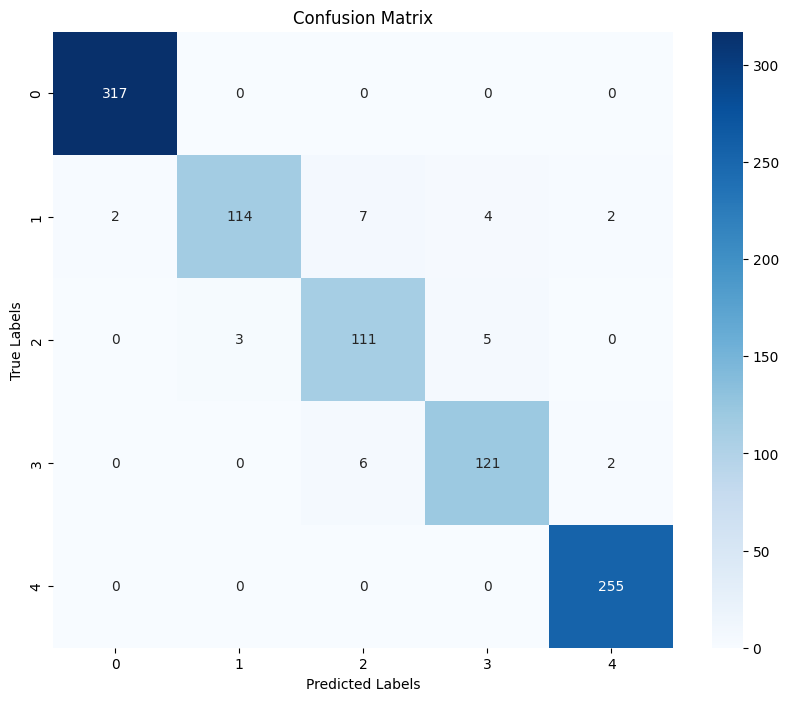

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Get predicted probabilities and predicted class labels
y_pred = model_no_depthwise.predict(x_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# Convert one-hot encoded y_test back to class labels
y_true = np.argmax(y_test, axis=1)

# Define class labels explicitly to ensure consistent ordering
labels = np.arange(y_pred.shape[1])

# Create confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred_classes, labels=labels)

# Compute class-wise metrics from sklearn report
report = classification_report(y_true, y_pred_classes, output_dict=True, labels=labels)

# Compute specificity, PLR, and NLR for each class
specificity = {}
plr = {}
nlr = {}

for i in labels:
    tp = conf_matrix[i, i]
    fn = np.sum(conf_matrix[i, :]) - tp
    fp = np.sum(conf_matrix[:, i]) - tp
    tn = np.sum(conf_matrix) - (tp + fp + fn)

    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0

    specificity[i] = spec
    plr[i] = sens / (1 - spec) if (1 - spec) > 0 else np.inf
    nlr[i] = (1 - sens) / spec if spec > 0 else np.inf

# Print class-wise results including PLR and NLR
print("Class-wise metrics:")
for label in labels:
    print(f"Class {label}:")
    print(f"  Precision   : {report[str(label)]['precision']:.4f}")
    print(f"  Recall      : {report[str(label)]['recall']:.4f}")
    print(f"  Specificity : {specificity[label]:.4f}")
    print(f"  PLR         : {plr[label]:.4f}")
    print(f"  NLR         : {nlr[label]:.4f}")
    print(f"  F1-Score    : {report[str(label)]['f1-score']:.4f}")
    print()

# Compute AUC if applicable (multi-class)
if y_pred.shape[1] > 1:
    # Using 'ovr' for one-vs-rest AUC for multi-class
    auc = roc_auc_score(y_test, y_pred, multi_class="ovr")
    print(f"Overall AUC: {auc:.4f}")

# Plot confusion matrix using seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels,
            yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [25]:
from sklearn.metrics import roc_auc_score

# Assuming y_test is one-hot encoded and y_pred are predicted probabilities

n_classes = y_test.shape[1]

for i in range(n_classes):
    # True binary labels for class i vs rest
    y_true_binary = y_test[:, i]
    # Predicted probabilities for class i
    y_pred_prob = y_pred[:, i]

    auc_per_class = roc_auc_score(y_true_binary, y_pred_prob)
    print(f"AUC for class {i}: {auc_per_class:.4f}")

AUC for class 0: 1.0000
AUC for class 1: 0.9871
AUC for class 2: 0.9919
AUC for class 3: 0.9960
AUC for class 4: 0.9994


### Grad-CAM for LFANet-NoDepthwise

/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=['Tensor(shape=(1, 128, 128, 3))']
  warnings.warn(msg)


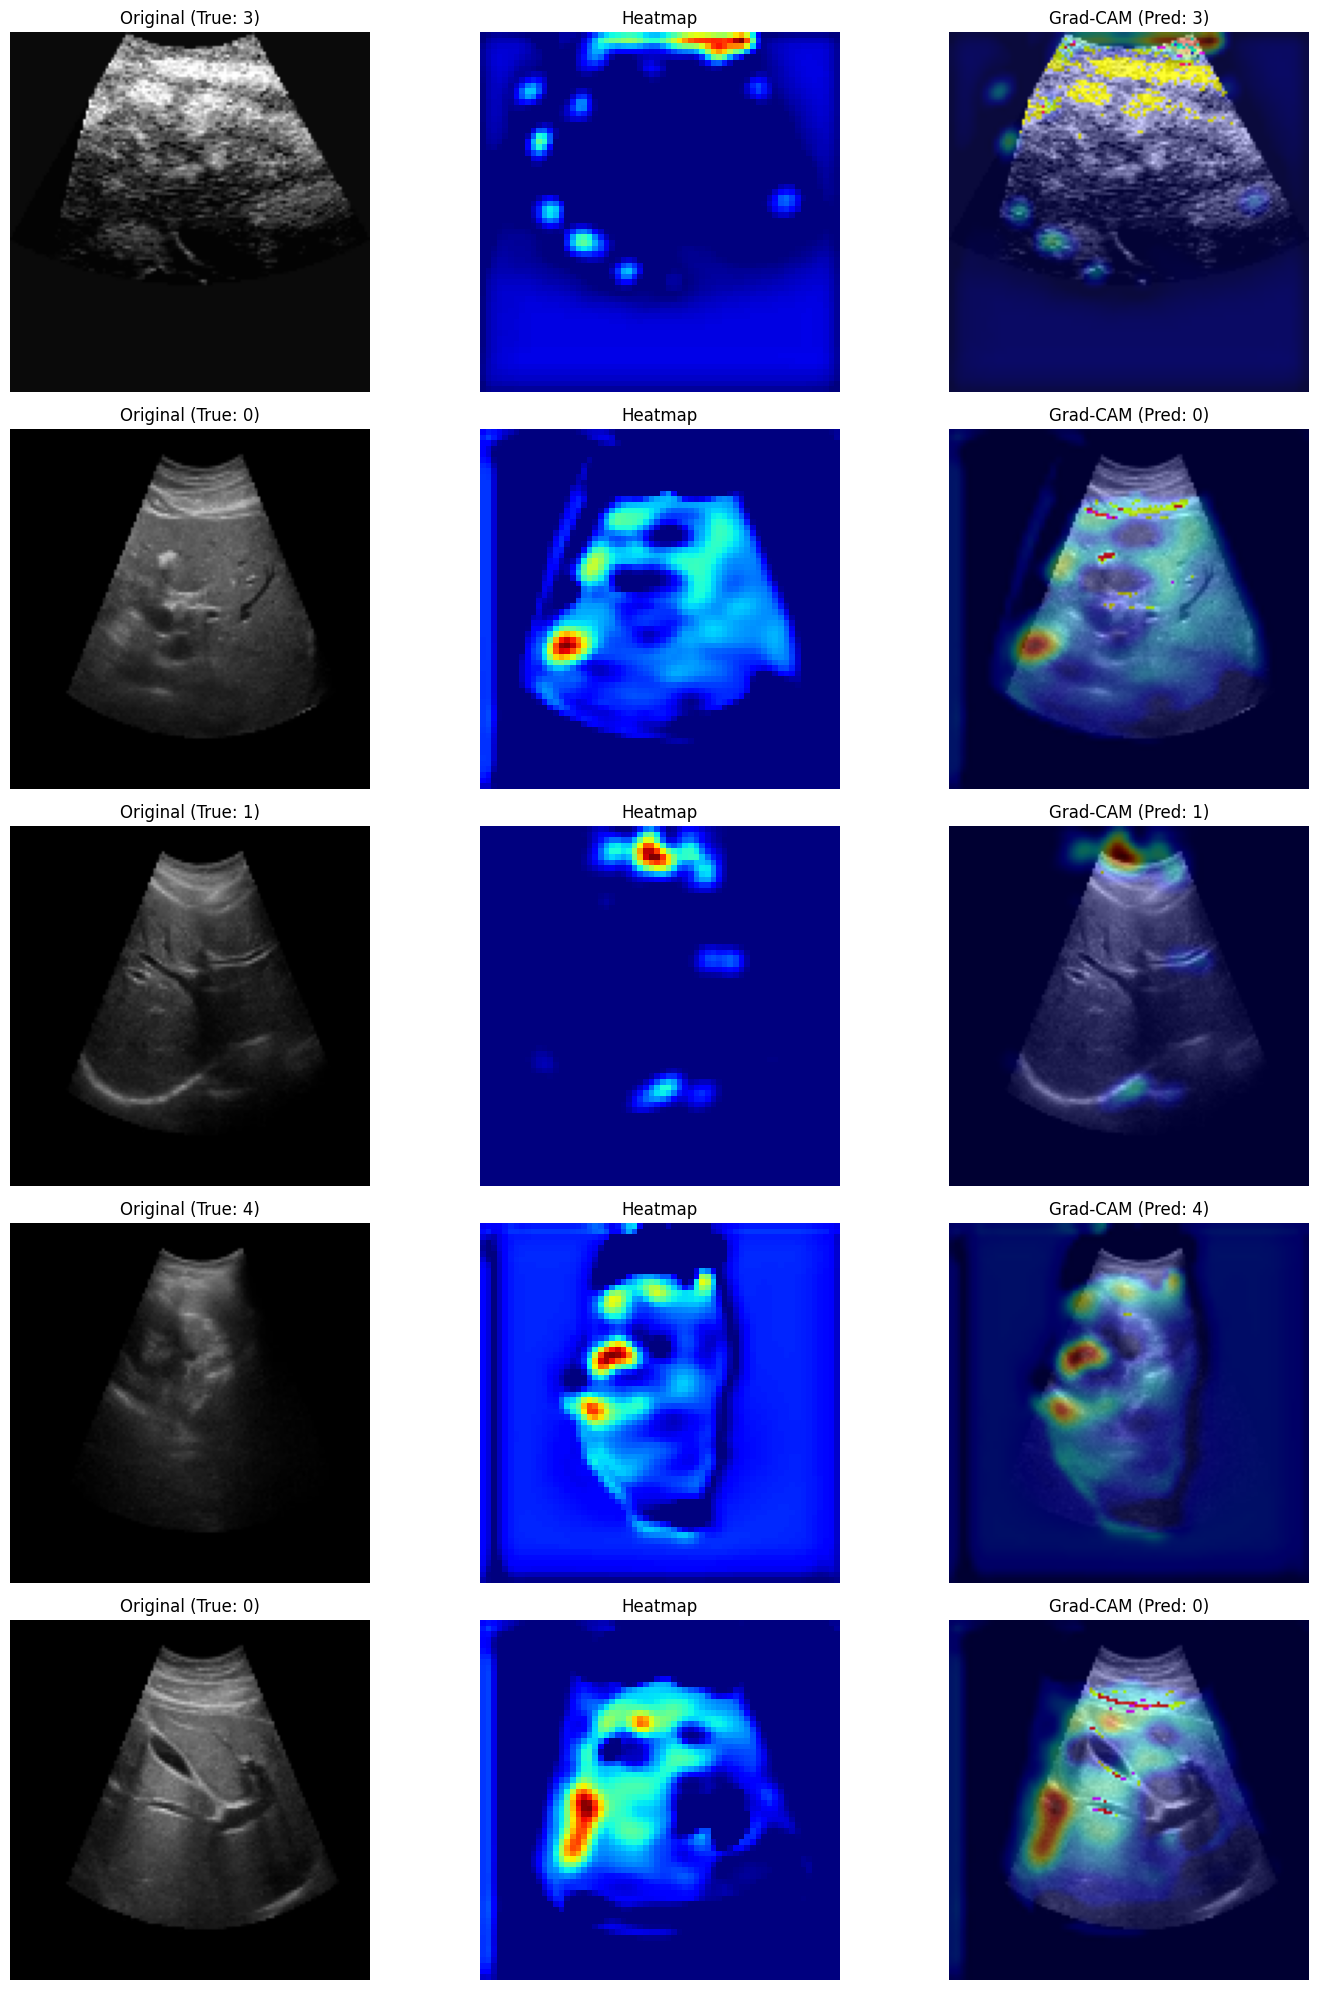

In [26]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from zipfile import ZipFile

# --- CONFIGURATION ---
output_dir = "gradcam_outputs_no_depthwise"
zip_filename = "gradcams_no_depthwise.zip"
img_size = (128, 128)
max_images_to_display = 5
# ----------------------

def get_img_array_from_tensor(img_tensor, size):
    # Reshape and resize if necessary
    img = tf.image.resize(img_tensor, size)
    img = tf.expand_dims(img, axis=0)
    return img

def find_last_conv_layer(model):
    for layer in reversed(model.layers):
        # Look for Conv2D or SeparableConv2D
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.SeparableConv2D)):
            # Ensure it's not the final classification layer if it's a 1x1 conv for output
            if len(layer.get_weights()) > 0: # Check if it has learnable weights
                return layer.name
    return None

# Automatically determine the last convolutional layer name
last_conv_layer_name = find_last_conv_layer(model_no_depthwise)
if last_conv_layer_name is None:
    print("Could not find a convolutional layer for Grad-CAM.")

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy(), int(pred_index)

def save_and_display_gradcam_overlay(image, heatmap, alpha=0.4):
    heatmap = np.uint8(255 * heatmap)
    jet = plt.colormaps.get_cmap("jet") # Use plt.colormaps.get_cmap
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap]

    jet_heatmap = Image.fromarray((jet_heatmap * 255).astype(np.uint8))
    jet_heatmap = jet_heatmap.resize((image.shape[1], image.shape[0]))
    jet_heatmap = np.array(jet_heatmap)

    superimposed_img = jet_heatmap * alpha + image
    superimposed_img = np.uint8(superimposed_img)
    return superimposed_img


# --- Visualize sample Grad-CAMs ---
if last_conv_layer_name:
    plt.figure(figsize=(15, max_images_to_display * 4))

    # Remove the last layer from the model for Grad-CAM (if it's the softmax output)
    # Check if the last layer is a Dense layer before removing, as some models might end with conv
    if isinstance(model_no_depthwise.layers[-1], tf.keras.layers.Dense) and model_no_depthwise.layers[-1].activation == tf.keras.activations.softmax:
        model_for_gradcam = tf.keras.models.Model(model_no_depthwise.inputs, model_no_depthwise.layers[-2].output)
    else:
        model_for_gradcam = model_no_depthwise

    for idx in range(min(max_images_to_display, len(x_test))):
        img = x_test[idx]
        true_label = np.argmax(y_test[idx]) if y_test.ndim == 2 else y_test[idx]

        # Prepare image for model
        img_array = get_img_array_from_tensor(img, img_size)

        # Generate heatmap
        heatmap, pred_class = make_gradcam_heatmap(img_array, model_no_depthwise, last_conv_layer_name)

        # Convert image back to uint8
        img_uint8 = np.uint8(img * 255)

        # Create superimposed image
        superimposed_img = save_and_display_gradcam_overlay(img_uint8, heatmap)

        # Display original image
        plt.subplot(max_images_to_display, 3, idx * 3 + 1)
        plt.imshow(img_uint8)
        plt.title(f"Original (True: {true_label})")
        plt.axis('off')

        # Display heatmap
        plt.subplot(max_images_to_display, 3, idx * 3 + 2)
        plt.imshow(heatmap, cmap='jet')
        plt.title("Heatmap")
        plt.axis('off')

        # Display superimposed image
        plt.subplot(max_images_to_display, 3, idx * 3 + 3)
        plt.imshow(superimposed_img)
        plt.title(f"Grad-CAM (Pred: {pred_class})")
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Grad-CAM visualization skipped as no suitable convolutional layer was found.")